# Shape only vs voltage with gains: L2 on isolated EODs (4-fish, Kaden masks, 10 cm / 5×)

EODs: the sure-emitter EODs at **10 cm / 5×** from all five videos.
- **Sure emitter**: midline ≥ 10 cm from every other fish's, predicted |v| at its top pair p* ≥ 5× every other fish's, largest
  recorded |v| at p* with the predicted sign, and only one fish passing.
- **Prediction** m: my model (BEM conductivities, sink at the tail tip, unit current, × −1) for that fish.
- **Recorded** r: the 10-pair peak pattern (V).

**Both errors on the same scale: divided by the recorded peak max|r|.**
- **Shape only**: $\lVert r/\max|r| - m/\max|m| \rVert = \lVert r - \hat r_{\text{shape}} \rVert / \max|r|$ with
  $\hat r_{\text{shape}} = m \cdot \max|r| / \max|m|$, i.e. the prediction scaled per EOD so that its peak equals the recorded peak.
- **Voltage with gains**: $\lVert r - a_f\, b_p\, m \rVert / \max|r|$, with the per-fish gain $a_f$ and per-pair gain $b_p$ of
  the per-fish × per-pair fit made on the **other four videos** (held out), so no per-EOD information enters the prediction.

So the two differ only in how the prediction gets its size: from this EOD's own recorded peak (shape only), or from fixed
fish and pair gains (voltage).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
SRC = f'{BASE}/fish_pair_factors_iso10cm_dom5'
OUT = f'{BASE}/fish_pair_factors_threshold_grid/l2_isolated'; os.makedirs(OUT, exist_ok=True)
COL = {'shape only': '#A9A9A3', 'voltage with gains': '#3F3F3B'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
peak = lambda x: np.abs(x).max(axis=-1, keepdims=True)

S = pd.read_csv(f'{SRC}/sure_emitter_eods.csv')
H = pd.read_csv(f'{SRC}/factors_fit_on_4_videos.csv').query("model == 'per-fish × per-pair (4 + 10)'").set_index('factor')
frames = []
for t, g in S.groupby('video', sort=False):
    z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    pick = pd.read_csv(f'{BASE}/{t}/eod_assignments.csv', usecols=['fish | mine, shape'])['fish | mine, shape'].fillna('').to_numpy()
    r = g.row.to_numpy(); fi = g.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy()
    R = z['recorded_peak'][r]; M = z['mine_unit_current'][r, fi]
    a = H.loc[[f'fish {f}' for f in LET], f'fit without {t}'].to_numpy(); b = H.loc[[f'pair {p}' for p in range(1, 11)], f'fit without {t}'].to_numpy()
    out = g[['video', 'row', 'Frame', 'emitter', 'pair p* (1-10)', 'gap (cm)']].copy()
    out['shape rule picks the same fish'] = pick[r] == g.emitter.to_numpy()
    out['max |r| (V)'] = peak(R)[:, 0]
    out['shape only'] = np.linalg.norm(R / peak(R) - M / peak(M), axis=1)
    out['voltage with gains'] = np.linalg.norm(R - a[fi, None] * b[None] * M, axis=1) / peak(R)[:, 0]
    frames.append(out)
D = pd.concat(frames, ignore_index=True)
D.to_csv(f'{OUT}/l2_isolated_10cm_5x.csv', index=False)
print(f"{len(D)} EODs; my shape rule picks the sure emitter in {D['shape rule picks the same fish'].mean() * 100:.1f}%")

G = D.groupby('emitter')
T = pd.DataFrame({'n EODs': G.size(), 'median L2, shape only': G['shape only'].median(),
                  'median L2, voltage with gains': G['voltage with gains'].median(),
                  '% EODs where voltage error < shape error': G[['voltage with gains', 'shape only']].apply(lambda d: (d['voltage with gains'] < d['shape only']).mean() * 100)})
T.loc['all'] = [len(D), D['shape only'].median(), D['voltage with gains'].median(), (D['voltage with gains'] < D['shape only']).mean() * 100]
T['n EODs'] = T['n EODs'].astype(int)
T.index = [f'fish {i}' if i != 'all' else 'all fish' for i in T.index]
T.to_csv(f'{OUT}/l2_isolated_10cm_5x_medians.csv')
display(T.round(3))

26926 EODs; my shape rule picks the sure emitter in 99.0%


,n EODs,"median L2, shape only","median L2, voltage with gains",% EODs where voltage error < shape error
fish A,6257,0.209,0.439,7.991
fish B,15559,0.225,0.355,10.277
fish C,1990,0.193,0.389,10.402
fish D,3120,0.200,0.584,4.712
all fish,26926,0.219,0.392,9.110


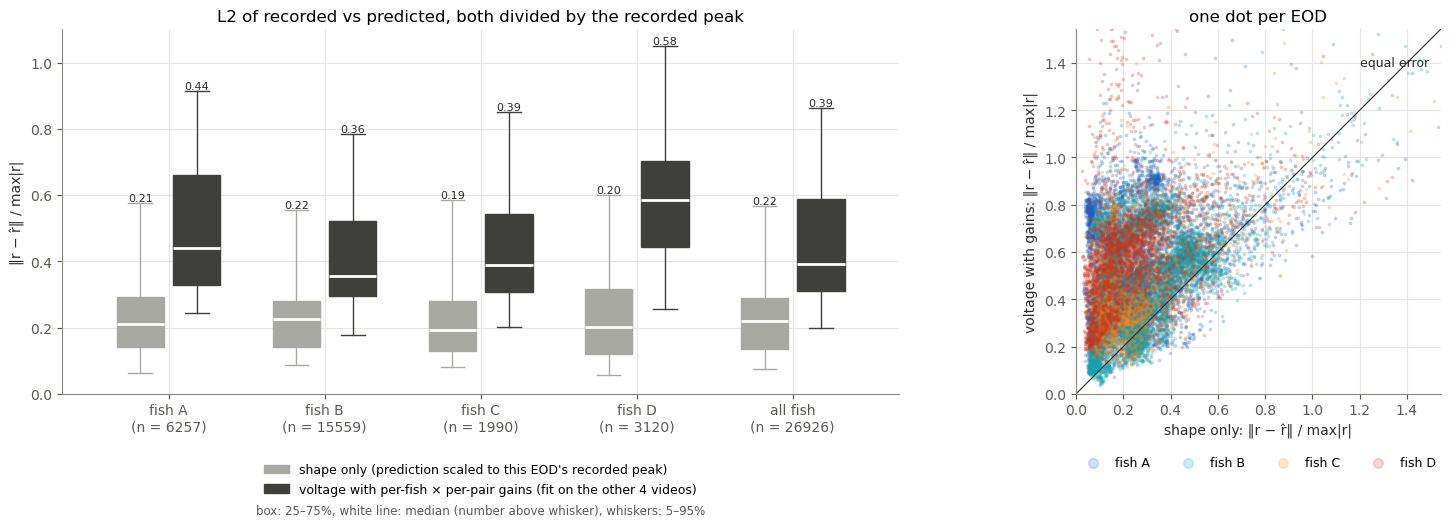

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axs[0]
groups = list(LET) + ['all']; w = 0.36
for k, (m, c) in enumerate(COL.items()):
    data = [D.loc[D.emitter == f, m].to_numpy() if f != 'all' else D[m].to_numpy() for f in groups]
    pos = np.arange(len(groups)) + (k - 0.5) * w
    ax.boxplot(data, positions=pos, widths=w * 0.85, whis=(5, 95), showfliers=False, patch_artist=True,
               medianprops=dict(color='white', lw=2), whiskerprops=dict(color=c), capprops=dict(color=c), boxprops=dict(facecolor=c, edgecolor=c))
    for x, v in zip(pos, data):
        ax.text(x, np.percentile(v, 95), f'{np.median(v):.2f}', ha='center', va='bottom', fontsize=8, color='#2b2b2b')
ax.set(xticks=range(len(groups)), xticklabels=[f'fish {f}\n(n = {(D.emitter == f).sum()})' if f != 'all' else f'all fish\n(n = {len(D)})' for f in groups],
       ylabel='‖r − r̂‖ / max|r|', title='L2 of recorded vs predicted, both divided by the recorded peak', ylim=(0, None))
ax.legend(handles=[Patch(color=COL['shape only'], label='shape only (prediction scaled to this EOD\'s recorded peak)'),
                   Patch(color=COL['voltage with gains'], label='voltage with per-fish × per-pair gains (fit on the other 4 videos)')],
          frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=9)
ax.text(0.5, -0.33, 'box: 25–75%, white line: median (number above whisker), whiskers: 5–95%', transform=ax.transAxes,
        ha='center', fontsize=8.5, color='#5a5a55')

ax = axs[1]
lim = np.percentile(np.r_[D['shape only'], D['voltage with gains']], 99)
for j, f in enumerate(LET):
    d = D[D.emitter == f]
    ax.scatter(d['shape only'], d['voltage with gains'], s=3, alpha=0.2, color=['#1F5FBF', '#17A0B0', '#F08A24', '#C8361E'][j], label=f'fish {f}')
ax.plot([0, lim], [0, lim], color='#2b2b2b', lw=0.8)
ax.text(lim * 0.97, lim * 0.9, 'equal error', ha='right', fontsize=9, color='#2b2b2b', rotation=0)
ax.set(xlim=(0, lim), ylim=(0, lim), aspect='equal', xlabel='shape only: ‖r − r̂‖ / max|r|', ylabel='voltage with gains: ‖r − r̂‖ / max|r|',
       title='one dot per EOD')
ax.legend(markerscale=4, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=9)
plt.tight_layout(); fig.savefig(f'{OUT}/l2_isolated_10cm_5x_shape_vs_voltage.png', dpi=120, bbox_inches='tight'); plt.show()